**Pharma Sales Analysis**

In [23]:
# importing data using pandas
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('salesmonthly.csv')
df.head()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
0,2014-01-31,127.69,99.090,152.100,878.030,354.0,50.0,112.0,48.2
1,2014-02-28,133.32,126.050,177.000,1001.900,347.0,31.0,122.0,36.2
2,2014-03-31,137.44,92.950,147.655,779.275,232.0,20.0,112.0,85.4
3,2014-04-30,113.10,89.475,130.900,698.500,209.0,18.0,97.0,73.7
4,2014-05-31,101.79,119.933,132.100,628.780,270.0,23.0,107.0,123.7


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   datum   70 non-null     object 
 1   M01AB   70 non-null     float64
 2   M01AE   70 non-null     float64
 3   N02BA   70 non-null     float64
 4   N02BE   70 non-null     float64
 5   N05B    70 non-null     float64
 6   N05C    70 non-null     float64
 7   R03     70 non-null     float64
 8   R06     70 non-null     float64
dtypes: float64(8), object(1)
memory usage: 5.1+ KB


In [42]:
# Convert date column into datetime
df['datum'] = pd.to_datetime(df['datum'])
df.head()


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
0,2014-01-31,127.69,99.090,152.100,878.030,354.0,50.0,112.0,48.2
1,2014-02-28,133.32,126.050,177.000,1001.900,347.0,31.0,122.0,36.2
2,2014-03-31,137.44,92.950,147.655,779.275,232.0,20.0,112.0,85.4
3,2014-04-30,113.10,89.475,130.900,698.500,209.0,18.0,97.0,73.7
4,2014-05-31,101.79,119.933,132.100,628.780,270.0,23.0,107.0,123.7


In [17]:
# Checking wheathet Date and time format got changed or not
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   datum   70 non-null     datetime64[ns]
 1   M01AB   70 non-null     float64       
 2   M01AE   70 non-null     float64       
 3   N02BA   70 non-null     float64       
 4   N02BE   70 non-null     float64       
 5   N05B    70 non-null     float64       
 6   N05C    70 non-null     float64       
 7   R03     70 non-null     float64       
 8   R06     70 non-null     float64       
dtypes: datetime64[ns](1), float64(8)
memory usage: 5.1 KB


In [20]:
# Identify ATC categories
atc_columns = df.columns.drop('datum')

# Check dataset
print(df.shape)
display(df.head())

(70, 9)


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
0,2014-01-31,127.69,99.090,152.100,878.030,354.0,50.0,112.0,48.2
1,2014-02-28,133.32,126.050,177.000,1001.900,347.0,31.0,122.0,36.2
2,2014-03-31,137.44,92.950,147.655,779.275,232.0,20.0,112.0,85.4
3,2014-04-30,113.10,89.475,130.900,698.500,209.0,18.0,97.0,73.7
4,2014-05-31,101.79,119.933,132.100,628.780,270.0,23.0,107.0,123.7


## **Question 1.** What are the total sales quantities for each drug category (ATC code)?

In [21]:
total_sales = df[atc_columns].sum().sort_values(ascending=False)
total_sales

,0
N02BE,62477.945
N05B,18348.300
R03,11737.250
M01AB,10499.440
M01AE,8156.000
N02BA,8051.459
R06,6066.380
N05C,1249.000


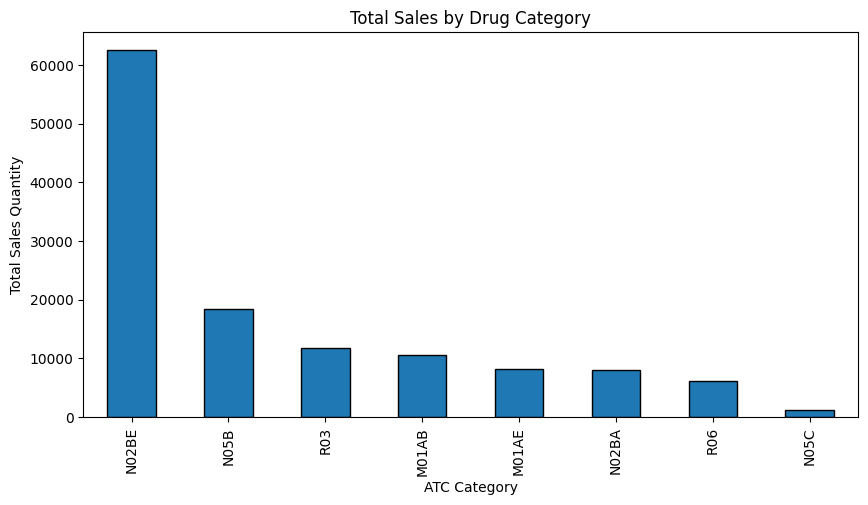

In [29]:
plt.figure(figsize=(10,5))

total_sales.plot(kind='bar', edgecolor='black')

plt.title('Total Sales by Drug Category')
plt.xlabel('ATC Category')
plt.ylabel('Total Sales Quantity')
plt.show()

## **Question 2.** Which individual drug brands have the highest total sales?

In [40]:
top_brands = total_sales.head(1)
top_brands

,0
N02BE,62477.945


## **Question 3.** Which three drugs have the highest sales in January 2015, July 2016 and September 2017?

In [62]:
# target months
months = ['2015-01', '2016-07', '2017-09']

# Identify ATC columns
atc_columns = df.columns.drop('datum')

# Find top 3 categories for each month
for month in months:

    monthly_data = df[
        df['datum'].dt.strftime('%Y-%m') == month
    ]

    sales = monthly_data[atc_columns].sum()

    top_3 = sales.nlargest(3)

    print(f"\nTop 3 categories for {month}:")
    print(top_3)


Top 3 categories for 2015-01:
N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

Top 3 categories for 2016-07:
N02BE    652.362
N05B     240.000
M01AB    203.970
dtype: float64

Top 3 categories for 2017-09:
N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64


## **Question 4.** Which drug has sold the most often in 2017?

In [56]:
# Filter 2017 data
df_2017 = df[df['datum'].dt.year == 2017]

# Calculate category-wise sales
sales_2017 = df_2017[atc_columns].sum().sort_values(
    ascending=False
)

print(sales_2017)

# Identify highest-selling category
print("\nHighest selling category:", sales_2017.idxmax())
print("Total sales:", sales_2017.max())

N02BE    7674.919
N05B     2078.000
R03      1732.000
M01AB    1653.790
M01AE    1214.485
N02BA    1091.150
R06       919.610
N05C      142.000
dtype: float64

Highest selling category: N02BE
Total sales: 7674.919000000002


## **Question 5.** Which drug category has the highest average daily sales?

In [58]:
# Total calendar days represented by the dataset
total_days = df['datum'].dt.days_in_month.sum()

# Calculate average daily sales
avg_daily_sales = (
    df[atc_columns].sum() / total_days
).sort_values(ascending=False)

print(avg_daily_sales)

N02BE    29.332369
N05B      8.614225
R03       5.510446
M01AB     4.929315
M01AE     3.829108
N02BA     3.780028
R06       2.848066
N05C      0.586385
dtype: float64
